In [ ]:
from pathlib import Path
from PIL import Image, UnidentifiedImageError
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import shutil
import hashlib
from sklearn.model_selection import train_test_split

PROJECT_DIR = Path(r"C:\BrainScan-v2")
DATA_DIR = Path(r"C:\BrainScan\Data")
OUTPUT_DIR = PROJECT_DIR / "data_split"

extensions_valides = {".jpg", ".jpeg", ".png", ".bmp"}

records=[]
invalide_file=[]

if not DATA_DIR.exists():
    raise FileExistsError(f"Dataset introuvable : {DATA_DIR}")


class_dirs =sorted(
    folders for folders in DATA_DIR.iterdir()
    if folders.is_dir()
)

if not class_dirs:
    raise ValueError("aucune doccier de classe trouve")

for class_dirs in class_dirs:
    class_name = class_dirs.name

    for file_path in class_dirs.rglob("*"):
        # pour ignore les docciers
        if not file_path.is_file():
            continue
        # virifier lextension
        if file_path.suffix.lower() not in extensions_valides:
            invalide_file.append(str(file_path))
            continue

        try:
            with Image.open(file_path) as image:
                image.verify()

            records.append({
                "image_path":str(file_path),
                "class_name":class_name
            })
        except (OSError,ValueError,UnidentifiedImageError):
            invalide_file.append(str(file_path))

# print("Nombre d'images dans records :", len(records))



In [3]:
df = pd.DataFrame(records)

if df.empty:
    raise ValueError("aucun image valide trouve.")

print("class detecter :")
print(sorted(df["class_name"].unique()))
print("nombre dimages valides :",len(df))
print("nombre des fichier ignorer : ",len(invalide_file))

print("nombre des imgaes par classe :  \n", df["class_name"].value_counts().sort_index())


class detecter :
['glioma', 'meningioma', 'notumor', 'pituitary']
nombre dimages valides : 7023
nombre des fichier ignorer :  7
nombre des imgaes par classe :  
 class_name
glioma        1621
meningioma    1645
notumor       2000
pituitary     1757
Name: count, dtype: int64


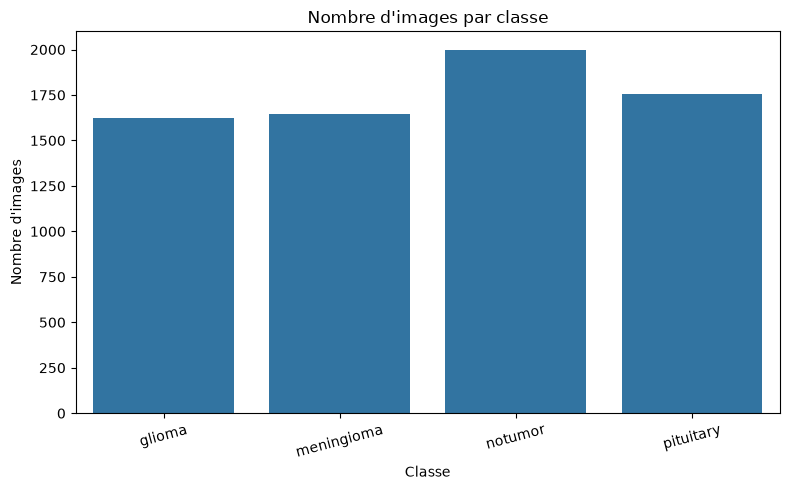

In [4]:


# la visualisation des distribution des classes

plt.figure(figsize=(8,5))
sns.countplot(data=df,x="class_name",order=sorted(df["class_name"].unique()))
plt.title("Nombre d'images par classe")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()



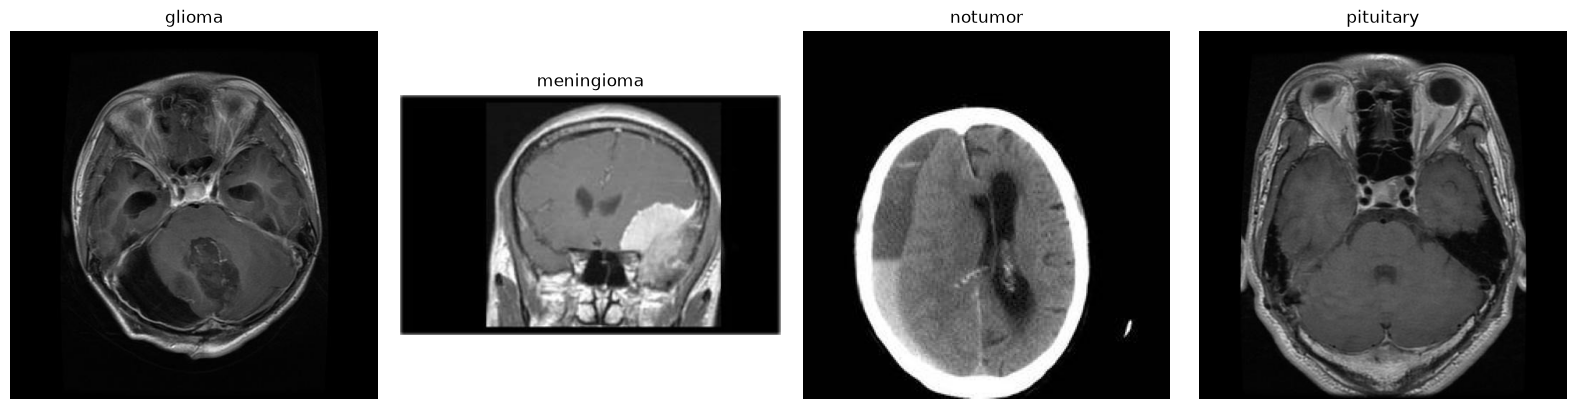

In [5]:

# une img par classe 
classes=sorted(df["class_name"].unique())

fig,axes=plt.subplots(1,len(classes),figsize=(4*len(classes),4))
if len(classes)==1:
    axes=[axes]

for ax,class_name in zip(axes,classes):
    image_path=df.loc[
        df["class_name"]==class_name,"image_path"
    ].iloc[0]

    with Image.open(image_path) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:

# print("Nombre d'images dans records :", len(records))
# detection des doublons
import hashlib
from collections import defaultdict

hash_groups=defaultdict(list)

for item in records:
    image_path = item["image_path"]

    with open(image_path,"rb") as file:
        image_hash=hashlib.sha256(file.read()).hexdigest()

    hash_groups[image_hash].append(item)

unique_records=[]
duplicates_count=0
conflicts_count=0

for image_hash, items in hash_groups.items():
    classes={item["class_name"] for item in items}

    if len(classes)>1:
        conflicts_count += len(items)

        print("conflit de classes :",[str(item["image_path"]) for item in items])
        continue

    # garder un seul copie
    unique_records.append(items[0])
    duplicates_count += len(items)-1
records =unique_records

print("\nresultat de la detection des doublons :")
print("dublons supprimes de la liste :", duplicates_count)
print("fchiers exclus pour conflit de classes :", conflicts_count)
print("images uniques conservees :", len(records))


resultat de la detection des doublons :
dublons supprimes de la liste : 297
fchiers exclus pour conflit de classes : 0
images uniques conservees : 6726


In [7]:
image_paths = [item["image_path"] for item in records]
labels = [item["class_name"] for item in records]

train_path,temp_path,train_labels,temp_labels=(
    train_test_split(image_paths,labels,test_size=0.30,random_state=42,stratify=labels)
)

val_path,test_path,val_labels,test_labels=(
    train_test_split(temp_path,temp_labels,test_size=0.50,random_state=42,stratify=temp_labels)
)

# copier les imgs dans les doccier de sortie
split={
    "train":(train_path,train_labels),
    "val":(val_path,val_labels),
    "test":(test_path,test_labels),
}


for split_name,(paths,split_labels) in split.items():
    for image_path,class_name in zip(paths,split_labels):
        destination_dir=OUTPUT_DIR / split_name / class_name
        destination_dir.mkdir(parents=True,exist_ok=True)

        unique_id = hashlib.sha256(
            str(Path(image_path).resolve()).encode()
        ).hexdigest()[:12]

        image_path = Path(image_path)
        
        destination = destination_dir/(
            f"{unique_id}_{image_path.name}"
        )

        shutil.copy2(image_path,destination)

# afficher les resultat
print("\nRepartition des donnees :")

for split_name,(paths,split_labels) in split.items():
    print(f"\n{split_name.upper()} : {len(paths)} images")
    print(dict(sorted(Counter(split_labels).items())))


total = len(train_path) + len(val_path) +len(test_path)
print(f"\n total : {total} images")
print(f"doccier de sortie : {OUTPUT_DIR}")



Repartition des donnees :

TRAIN : 4708 images
{'glioma': 1134, 'meningioma': 1144, 'notumor': 1212, 'pituitary': 1218}

VAL : 1009 images
{'glioma': 243, 'meningioma': 245, 'notumor': 260, 'pituitary': 261}

TEST : 1009 images
{'glioma': 243, 'meningioma': 246, 'notumor': 259, 'pituitary': 261}

 total : 6726 images
doccier de sortie : C:\BrainScan-v2\data_split
